# Fraud Detection — Card Transactions

The fraud prevention team reviews suspicious transactions mostly by hand. As volume grows, this creates two risks: **fraud that slips through** and **legitimate customers blocked by mistake**.

This notebook explores the 2025 labelled history, builds a model to classify transactions as fraudulent or not, and classifies January 2026.

1. Data and quality
2. Where fraud happens
3. What drives fraud inside the risk windows
4. What changes over time
5. Exploration takeaways

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

DATA = Path("../data")
OUTPUTS = Path("../outputs")
OUTPUTS.mkdir(exist_ok=True)

TARGET = "flag_fraude"
FRAUD_COLOR = "#c0392b"
LEGIT_COLOR = "#2e86c1"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data and quality

In [2]:
def load(name):
    df = pd.read_csv(DATA / name, parse_dates=["datahora_transacao"])
    df["hour"] = df["datahora_transacao"].dt.hour
    df["month"] = df["datahora_transacao"].dt.month
    return df


history = load("transacoes_historico_2025.csv")
january = load("transacoes_jan2026.csv")
history[TARGET] = history[TARGET].astype(int)

print(f"History: {len(history):,} rows, {history['datahora_transacao'].min():%Y-%m-%d} to {history['datahora_transacao'].max():%Y-%m-%d}")
print(f"January 2026: {len(january):,} rows")
print(f"Fraud rate: {history[TARGET].mean():.2%} ({history[TARGET].sum():,} frauds)")
print(f"Missing values: {history.isna().sum().sum()} | Duplicated rows: {history.duplicated().sum()}")

History: 523,525 rows, 2025-01-01 to 2025-12-31
January 2026: 44,451 rows
Fraud rate: 3.91% (20,485 frauds)


Missing values: 0 | Duplicated rows: 0


No missing values and no duplicates. With 3.9% fraud, a model that always says "legitimate" is 96% accurate and useless, so **accuracy is not the metric**: we will look at precision, recall and the precision-recall curve.

In [3]:
history.nunique().sort_values().to_frame("unique values")

,unique values
flag_fraude,2
is_new_device,2
valor_categoria,3
device_type,3
cidade_regiao,3
turno,4
tipo_estabelecimento,6
cidade,7
nome_estabelecimento,10
month,12


Several columns are derived from others, so they add no information:

In [4]:
def is_function_of(df, source, derived):
    return df.groupby(source)[derived].nunique().max() == 1


redundant = {
    "turno ← hour": is_function_of(history, "hour", "turno"),
    "cidade_regiao ← cidade": is_function_of(history, "cidade", "cidade_regiao"),
    "tipo_estabelecimento ← nome_estabelecimento": is_function_of(history, "nome_estabelecimento", "tipo_estabelecimento"),
    "valor_categoria ← valor_transacao": is_function_of(history, "valor_transacao", "valor_categoria"),
}
pd.Series(redundant, name="fully determined")

turno ← hour                                   True
cidade_regiao ← cidade                         True
tipo_estabelecimento ← nome_estabelecimento    True
valor_categoria ← valor_transacao              True
Name: fully determined, dtype: bool

And some columns carry no signal. The AUC of a single column measures how well it alone ranks frauds above legitimate transactions: 0.5 is a coin flip.

In [5]:
def single_column_auc(df, column):
    auc = roc_auc_score(df[TARGET], df[column])
    return max(auc, 1 - auc)


signal = pd.Series({col: single_column_auc(history, col) for col in ["score_interno", "temperatura_celsius", "valor_transacao", "is_new_device"]})
signal.sort_values(ascending=False).to_frame("AUC alone")

,AUC alone
is_new_device,0.6982
valor_transacao,0.5301
temperatura_celsius,0.5176
score_interno,0.5011


In [6]:
print(f"codigo_postal: {history['codigo_postal'].nunique():,} values for {len(history):,} rows")
print(f"nome_cliente: {history['nome_cliente'].nunique():,} clients, about {len(history) / history['nome_cliente'].nunique():.0f} transactions each")

codigo_postal: 521,905 values for 523,525 rows
nome_cliente: 26,214 clients, about 20 transactions each


- **`score_interno` does not separate fraud (AUC 0.50).** This is a finding for the business: the internal score in use today behaves like a coin flip on this data.
- **`temperatura_celsius`** is noise, and **`codigo_postal`** is almost unique per row, so it works as an identifier, not a feature.
- `is_new_device` alone already reaches AUC 0.70.

## 2. Where fraud happens

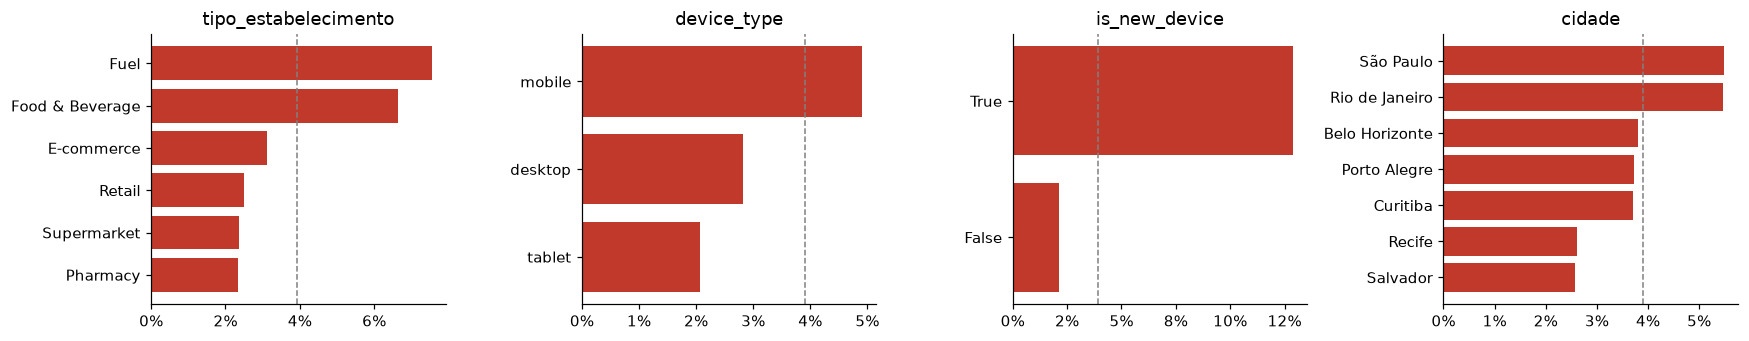

In [7]:
def fraud_rate_bars(df, columns):
    fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 3.2))
    for ax, column in zip(axes, columns):
        rates = df.groupby(column)[TARGET].mean().sort_values()
        ax.barh(rates.index.astype(str), rates.values, color=FRAUD_COLOR)
        ax.axvline(df[TARGET].mean(), color="grey", linestyle="--", linewidth=1)
        ax.set_title(column)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    fig.tight_layout()
    return fig


fraud_rate_bars(history, ["tipo_estabelecimento", "device_type", "is_new_device", "cidade"]);

Fuel and food stand out, and so do mobile, new devices and São Paulo / Rio de Janeiro. The strongest pattern, though, appears only when we cross **hour** with **merchant type**:

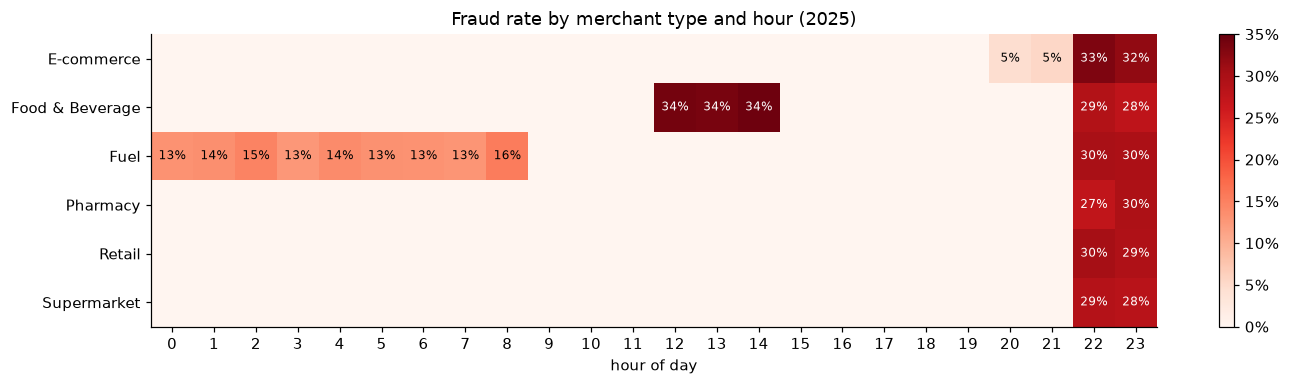

In [8]:
heat = history.pivot_table(index="tipo_estabelecimento", columns="hour", values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(figsize=(13, 3.6))
image = ax.imshow(heat.values, cmap="Reds", aspect="auto", vmin=0, vmax=0.35)
ax.set_xticks(range(24), labels=heat.columns)
ax.set_yticks(range(len(heat)), labels=heat.index)
for (row, col), rate in np.ndenumerate(heat.values):
    if rate >= 0.04:
        ax.text(col, row, f"{rate:.0%}", ha="center", va="center", fontsize=8, color="white" if rate > 0.2 else "black")
ax.set_xlabel("hour of day")
ax.set_title("Fraud rate by merchant type and hour (2025)")
fig.colorbar(image, ax=ax, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
fig.savefig(OUTPUTS / "fraud_heatmap.png", bbox_inches="tight")

In [9]:
RISK_THRESHOLD = 0.10

risk_cells = heat.stack()
risk_cells = risk_cells[risk_cells > RISK_THRESHOLD]


def in_risk_window(df):
    keys = pd.MultiIndex.from_arrays([df["tipo_estabelecimento"], df["hour"]])
    return keys.isin(risk_cells.index)


history["risk_window"] = in_risk_window(history)
coverage = history.groupby("risk_window").agg(transactions=(TARGET, "size"), frauds=(TARGET, "sum"))
coverage["share_of_transactions"] = coverage["transactions"] / coverage["transactions"].sum()
coverage["share_of_frauds"] = coverage["frauds"] / coverage["frauds"].sum()
coverage["fraud_rate"] = coverage["frauds"] / coverage["transactions"]
coverage

,transactions,frauds,share_of_transactions,share_of_frauds,fraud_rate
risk_window,,,,,
False,447420,446,0.8546,0.0218,0.0010
True,76105,20039,0.1454,0.9782,0.2633


**Fraud is concentrated in a few time windows, each tied to a merchant type:**

- Fuel, from midnight to 8 a.m. (about 13%)
- Food & Beverage, from 12 p.m. to 2 p.m. (about 34%)
- Any merchant, from 10 p.m. to midnight (about 29%)

These windows hold about 15% of the transactions but **98% of the frauds**. Outside them, fraud is close to zero.

## 3. What drives fraud inside the risk windows

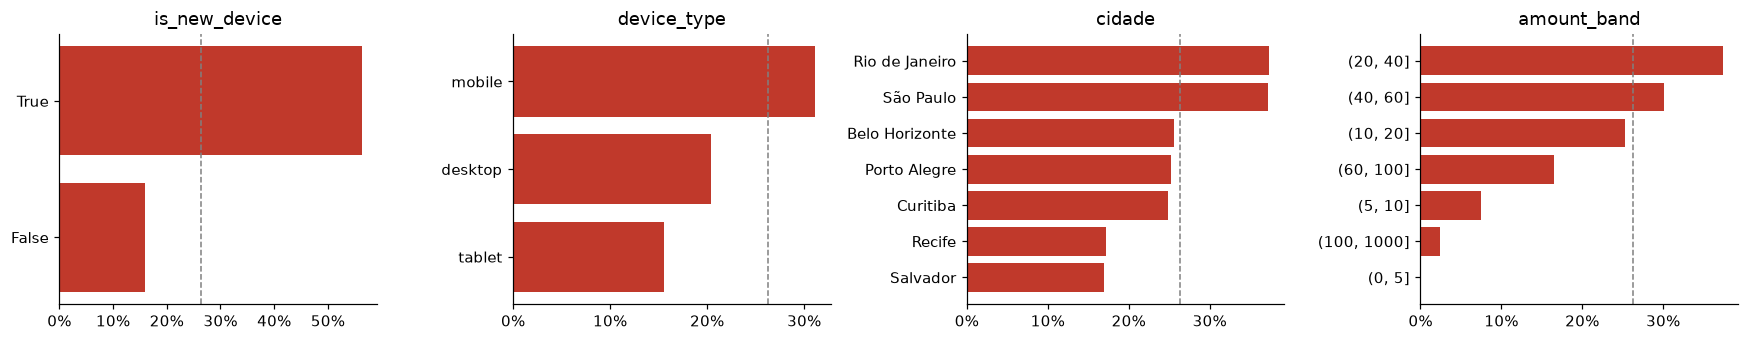

In [10]:
window = history[history["risk_window"]].copy()
window["amount_band"] = pd.cut(window["valor_transacao"], [0, 5, 10, 20, 40, 60, 100, 1000])

fraud_rate_bars(window, ["is_new_device", "device_type", "cidade", "amount_band"]);

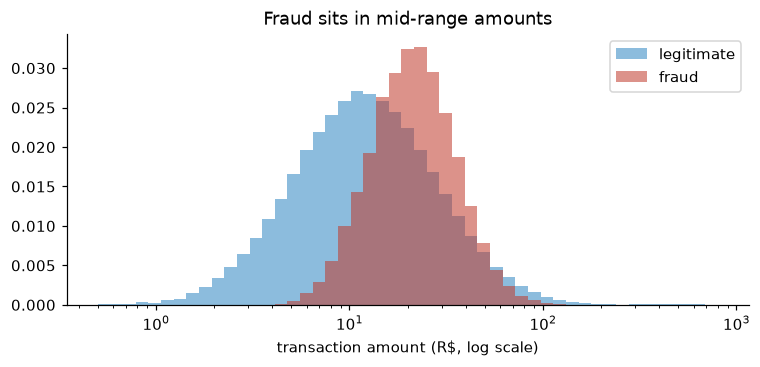

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(np.log10(0.5), np.log10(800), 50)
for label, color, name in [(0, LEGIT_COLOR, "legitimate"), (1, FRAUD_COLOR, "fraud")]:
    values = history.loc[history[TARGET] == label, "valor_transacao"]
    ax.hist(values, bins=bins, density=True, alpha=0.55, color=color, label=name)
ax.set_xscale("log")
ax.set_xlabel("transaction amount (R$, log scale)")
ax.set_title("Fraud sits in mid-range amounts")
ax.legend();

Inside the windows, the risk rises with:

- **a new device** (about 56% fraud, against 16% on a known device);
- **mobile**, and **São Paulo or Rio de Janeiro** (about 37%, against 17% in Recife and Salvador);
- **amounts between R$ 10 and R$ 60**. There is no fraud under R$ 5 or above R$ 220: fraudsters keep purchases ordinary so they do not draw attention.

In [12]:
ordered = history.sort_values("datahora_transacao")
previous_frauds = ordered.groupby("nome_cliente")[TARGET].cumsum() - ordered[TARGET]
ordered.groupby(previous_frauds.clip(upper=3))[TARGET].agg(fraud_rate="mean", transactions="size").rename_axis("client's previous frauds")

,fraud_rate,transactions
client's previous frauds,,
0,0.0387,367546
1,0.0397,121526
2,0.0421,28250
3,0.0414,6203


A client's past frauds do not change the chance of a new one, so client history adds nothing here. In real card data it usually does; this is worth checking with the fraud team before production.

## 4. What changes over time

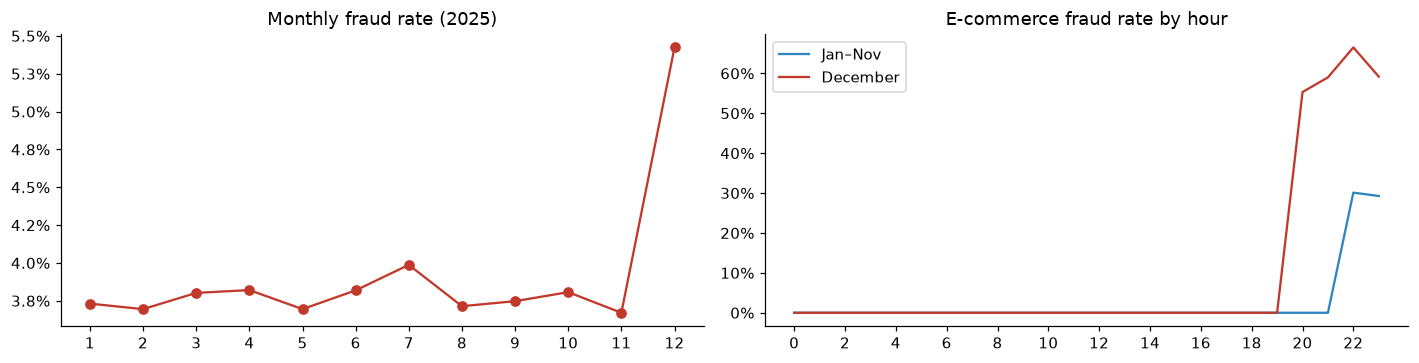

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))

monthly = history.groupby("month")[TARGET].mean()
axes[0].plot(monthly.index, monthly.values, marker="o", color=FRAUD_COLOR)
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Monthly fraud rate (2025)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))

ecommerce = history[history["tipo_estabelecimento"] == "E-commerce"]
by_hour = ecommerce.pivot_table(index="hour", columns=ecommerce["month"] == 12, values=TARGET, aggfunc="mean")
axes[1].plot(by_hour.index, by_hour[False], color=LEGIT_COLOR, label="Jan–Nov")
axes[1].plot(by_hour.index, by_hour[True], color=FRAUD_COLOR, label="December")
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title("E-commerce fraud rate by hour")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
fig.tight_layout()

December brings a **new pattern**: e-commerce fraud starts at 8 p.m., which never happens in the rest of the year, and doubles at 10–11 p.m. (about 60% against 30%). The monthly rate jumps from about 3.7% to 5.4%. Two consequences for the model:

- validation must follow **time** (train on earlier months, test on later ones), never a random split;
- the final model must be **retrained with December** before scoring January, and monitored for new patterns.

In [14]:
comparison = pd.DataFrame({
    "2025": [history["valor_transacao"].mean(), history["is_new_device"].mean(), (history["hour"] >= 22).mean()],
    "Jan 2026": [january["valor_transacao"].mean(), january["is_new_device"].mean(), (january["hour"] >= 22).mean()],
}, index=["mean amount (R$)", "new device share", "share after 10 p.m."])
comparison

,2025,Jan 2026
mean amount (R$),43.9629,44.1299
new device share,0.1658,0.1651
share after 10 p.m.,0.0833,0.0834


January 2026 looks like 2025 on the main inputs, so the model trained on 2025 applies to it.

**About the label.** The model can only be as good as `flag_fraude`. Before production we would confirm with the fraud team how a transaction becomes "fraud" (chargeback, customer complaint, analyst decision) and how long that takes, since late confirmations make the most recent months look cleaner than they are.

## 5. Exploration takeaways

- **Keep:** hour, merchant type, new device, device type, city, amount.
- **Drop:** `score_interno` and `temperatura_celsius` (no signal), `codigo_postal` and `nome_cliente` (identifiers), and the columns derived from others.
- **Validate by time**, and retrain with December before classifying January.
- **The bar to beat** is a simple rule: "flag every transaction inside a risk window". A model is only worth it if it does better than that.